# 04. Multiclass Classification

## Objective
Classify network traffic into its original traffic categories using the cleaned CyberThreat dataset. This notebook evaluates a baseline and three machine-learning models using a leakage-aware train-test split.

**Target:** `Label`  
**Evaluation:** 80/20 grouped, stratified split where possible  
**Models:** Logistic Regression, Decision Tree, Random Forest

## 1. Import Libraries

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load the Processed Dataset

In [2]:
candidate_paths = [
    os.path.join("data", "processed", "CyberThreat_Master_Cleaned.csv"),
    os.path.join("..", "data", "processed", "CyberThreat_Master_Cleaned.csv"),
]

DATA_PATH = next((p for p in candidate_paths if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find CyberThreat_Master_Cleaned.csv. "
        "Run this notebook from the project root or notebooks folder."
    )

df = pd.read_csv(DATA_PATH, low_memory=False)
print("Dataset loaded:", DATA_PATH)
print("Shape:", df.shape)
display(df.head())

Dataset loaded: ..\data\processed\CyberThreat_Master_Cleaned.csv
Shape: (2791255, 78)


,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Day
0,192.168.10.5-104.16.207.165-54865-443-6,104.16.207.165,443.0,192.168.10.5,54865.0,6.0,7/7/2017 3:30,3.0,2.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Friday
1,192.168.10.5-104.16.28.216-55054-80-6,104.16.28.216,80.0,192.168.10.5,55054.0,6.0,7/7/2017 3:30,109.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Friday
2,192.168.10.5-104.16.28.216-55055-80-6,104.16.28.216,80.0,192.168.10.5,55055.0,6.0,7/7/2017 3:30,52.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Friday
3,192.168.10.16-104.17.241.25-46236-443-6,104.17.241.25,443.0,192.168.10.16,46236.0,6.0,7/7/2017 3:30,34.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Friday
4,192.168.10.5-104.19.196.102-54863-443-6,104.19.196.102,443.0,192.168.10.5,54863.0,6.0,7/7/2017 3:30,3.0,2.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Friday


## 3. Inspect Dataset and Target

In [3]:
TARGET_COLUMN = next(
    (c for c in df.columns if str(c).strip().lower() == "label"),
    None
)
if TARGET_COLUMN is None:
    raise KeyError("Could not find a target column named 'Label' (case-insensitive).")

df[TARGET_COLUMN] = df[TARGET_COLUMN].astype("string").str.strip()
df = df.dropna(subset=[TARGET_COLUMN])
df = df[df[TARGET_COLUMN] != ""].copy()

print("Number of classes:", df[TARGET_COLUMN].nunique())
print("Rows after removing missing target:", len(df))
display(df[TARGET_COLUMN].value_counts())

Number of classes: 15
Rows after removing missing target: 2791255


Label
BENIGN                        2247393
DoS Hulk                       230123
PortScan                       146111
DDoS                           128025
DoS GoldenEye                   10293
FTP-Patator                      7935
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1956
Web Attack – Brute Force         1507
Web Attack – XSS                  652
Infiltration                       36
Web Attack – Sql Injection         21
Heartbleed                         11
Name: count, dtype: Int64

## 4. Multiclass Traffic Distribution


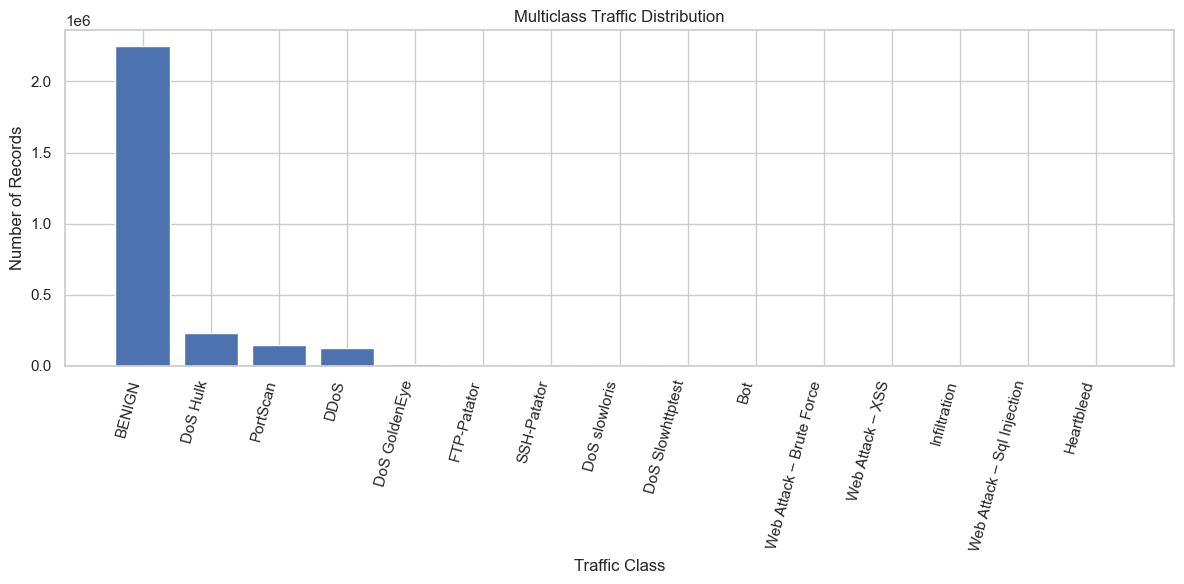

In [4]:
class_counts = df[TARGET_COLUMN].value_counts().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
plt.bar(class_counts.index.astype(str), class_counts.values)
plt.title("Multiclass Traffic Distribution")
plt.xlabel("Traffic Class")
plt.ylabel("Number of Records")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

## 5. Prepare Features and Target

The target label and binary target are excluded from the predictors. Timestamp and non-numeric identifier columns are also excluded. Numeric network-flow features are retained.

Missing values and infinite values are handled inside model pipelines so that imputation is learned from the training data only.

In [5]:
excluded_columns = [
    TARGET_COLUMN,
    "Binary_Label",
    "Timestamp",
    "Flow ID",
    "Src IP",
    "Source IP",
    "Dst IP",
    "Destination IP",
]

feature_df = df.drop(columns=[c for c in excluded_columns if c in df.columns], errors="ignore")
X = feature_df.select_dtypes(include=[np.number]).copy()
y = df[TARGET_COLUMN].copy()

# Replace infinite values with missing values; imputation occurs inside pipelines.
X = X.replace([np.inf, -np.inf], np.nan)

# Remove columns that contain no usable numeric information.
all_missing_columns = X.columns[X.isna().all()].tolist()
if all_missing_columns:
    X = X.drop(columns=all_missing_columns)

if X.shape[1] == 0:
    raise ValueError("No usable numeric features remain after feature preparation.")

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Excluded all-missing features:", all_missing_columns)

Feature matrix shape: (2791255, 72)
Target shape: (2791255,)
Excluded all-missing features: []


## 6. Remove Conflicting Feature Groups


In [6]:
# Hash identical feature rows so that identical records can be kept in the same split.
row_groups = pd.util.hash_pandas_object(X, index=False).astype("uint64")

group_label_counts = (
    pd.DataFrame({"group_id": row_groups, "label": y})
    .groupby("group_id")["label"]
    .nunique()
)

conflicting_group_ids = group_label_counts[group_label_counts > 1].index
conflict_mask = row_groups.isin(conflicting_group_ids)

print("Rows with feature groups having conflicting labels:", int(conflict_mask.sum()))
print("Conflicting feature groups:", len(conflicting_group_ids))

# Identical feature rows assigned to different classes cannot be used reliably.
if conflict_mask.any():
    X = X.loc[~conflict_mask].copy()
    y = y.loc[~conflict_mask].copy()
    row_groups = row_groups.loc[~conflict_mask].copy()

print("Rows after removing conflicting groups:", len(X))
print("Remaining classes:", y.nunique())
display(y.value_counts())

Rows with feature groups having conflicting labels: 0
Conflicting feature groups: 0
Rows after removing conflicting groups: 2791255
Remaining classes: 15


Label
BENIGN                        2247393
DoS Hulk                       230123
PortScan                       146111
DDoS                           128025
DoS GoldenEye                   10293
FTP-Patator                      7935
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1956
Web Attack – Brute Force         1507
Web Attack – XSS                  652
Infiltration                       36
Web Attack – Sql Injection         21
Heartbleed                         11
Name: count, dtype: Int64

## 7. Train-Test Split (Grouped and Stratified)

In [7]:
# StratifiedGroupKFold attempts to preserve class proportions while keeping
# identical feature rows together. The first fold is used as the hold-out test set.
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

train_idx, test_idx = next(splitter.split(X, y, groups=row_groups))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
groups_train, groups_test = row_groups.iloc[train_idx], row_groups.iloc[test_idx]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Train proportion:", len(X_train) / len(X))
print("Test proportion:", len(X_test) / len(X))

print("Overlapping feature groups:", len(set(groups_train) & set(groups_test)))
assert len(set(groups_train) & set(groups_test)) == 0, "Leakage: feature groups overlap!"

Training rows: 2232906
Testing rows: 558349
Train proportion: 0.799964890345024
Test proportion: 0.20003510965497598
Overlapping feature groups: 0


In [8]:
print("Training class distribution:")
display(y_train.value_counts())

print("Testing class distribution:")
display(y_test.value_counts())

missing_test_classes = sorted(set(y_train) - set(y_test))
print("Classes present in training but absent from test:", missing_test_classes)

Training class distribution:


Label
BENIGN                        1797626
DoS Hulk                       184059
PortScan                       116969
DDoS                           102571
DoS GoldenEye                    8163
FTP-Patator                      6355
SSH-Patator                      4755
DoS slowloris                    4678
DoS Slowhttptest                 4397
Bot                              1573
Web Attack – Brute Force         1194
Web Attack – XSS                  507
Infiltration                       33
Web Attack – Sql Injection         17
Heartbleed                          9
Name: count, dtype: Int64

Testing class distribution:


Label
BENIGN                        449767
DoS Hulk                       46064
PortScan                       29142
DDoS                           25454
DoS GoldenEye                   2130
FTP-Patator                     1580
SSH-Patator                     1142
DoS slowloris                   1118
DoS Slowhttptest                1102
Bot                              383
Web Attack – Brute Force         313
Web Attack – XSS                 145
Web Attack – Sql Injection         4
Infiltration                       3
Heartbleed                         2
Name: count, dtype: Int64

Classes present in training but absent from test: []


## 8. Define Evaluation Function

In [9]:
def evaluate_model(model_name, model, X_test, y_test):
    predictions = model.predict(X_test)
    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_test, predictions),
        "Macro Precision": precision_score(y_test, predictions, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_test, predictions, average="macro", zero_division=0),
        "Macro F1": f1_score(y_test, predictions, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_test, predictions, average="weighted", zero_division=0),
    }
    print(f"\\n===== {model_name} =====")
    print(classification_report(y_test, predictions, zero_division=0))
    return results, predictions

## 9. Majority-Class Baseline

In [10]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_results, baseline_predictions = evaluate_model(
    "Majority-Class Baseline", baseline, X_test, y_test
)

\n===== Majority-Class Baseline =====
                            precision    recall  f1-score   support

                    BENIGN       0.81      1.00      0.89    449767
                       Bot       0.00      0.00      0.00       383
                      DDoS       0.00      0.00      0.00     25454
             DoS GoldenEye       0.00      0.00      0.00      2130
                  DoS Hulk       0.00      0.00      0.00     46064
          DoS Slowhttptest       0.00      0.00      0.00      1102
             DoS slowloris       0.00      0.00      0.00      1118
               FTP-Patator       0.00      0.00      0.00      1580
                Heartbleed       0.00      0.00      0.00         2
              Infiltration       0.00      0.00      0.00         3
                  PortScan       0.00      0.00      0.00     29142
               SSH-Patator       0.00      0.00      0.00      1142
  Web Attack – Brute Force       0.00      0.00      0.00       313
Web Attac

## 10. Logistic Regression

In [11]:
logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

logistic_model.fit(X_train, y_train)
logistic_results, logistic_predictions = evaluate_model(
    "Logistic Regression", logistic_model, X_test, y_test
)

\n===== Logistic Regression =====
                            precision    recall  f1-score   support

                    BENIGN       1.00      0.81      0.90    449767
                       Bot       0.01      0.99      0.02       383
                      DDoS       0.90      1.00      0.95     25454
             DoS GoldenEye       0.53      0.98      0.68      2130
                  DoS Hulk       0.83      1.00      0.91     46064
          DoS Slowhttptest       0.34      0.99      0.51      1102
             DoS slowloris       0.33      0.99      0.50      1118
               FTP-Patator       0.46      1.00      0.63      1580
                Heartbleed       0.17      0.50      0.25         2
              Infiltration       0.00      0.67      0.00         3
                  PortScan       0.81      1.00      0.89     29142
               SSH-Patator       0.21      0.99      0.34      1142
  Web Attack – Brute Force       0.04      0.51      0.07       313
Web Attack – 

## 11. Decision Tree

In [12]:
decision_tree_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", DecisionTreeClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

decision_tree_model.fit(X_train, y_train)
decision_tree_results, decision_tree_predictions = evaluate_model(
    "Decision Tree", decision_tree_model, X_test, y_test
)

\n===== Decision Tree =====
                            precision    recall  f1-score   support

                    BENIGN       1.00      1.00      1.00    449767
                       Bot       0.97      0.98      0.98       383
                      DDoS       1.00      1.00      1.00     25454
             DoS GoldenEye       1.00      0.99      1.00      2130
                  DoS Hulk       1.00      1.00      1.00     46064
          DoS Slowhttptest       0.99      0.99      0.99      1102
             DoS slowloris       0.99      1.00      1.00      1118
               FTP-Patator       1.00      1.00      1.00      1580
                Heartbleed       1.00      0.50      0.67         2
              Infiltration       1.00      1.00      1.00         3
                  PortScan       1.00      1.00      1.00     29142
               SSH-Patator       1.00      1.00      1.00      1142
  Web Attack – Brute Force       0.86      0.87      0.87       313
Web Attack – Sql In

## 12. Random Forest

In [13]:
random_forest_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)
random_forest_results, random_forest_predictions = evaluate_model(
    "Random Forest", random_forest_model, X_test, y_test
)

\n===== Random Forest =====
                            precision    recall  f1-score   support

                    BENIGN       1.00      1.00      1.00    449767
                       Bot       0.98      0.95      0.96       383
                      DDoS       1.00      1.00      1.00     25454
             DoS GoldenEye       1.00      0.99      1.00      2130
                  DoS Hulk       1.00      1.00      1.00     46064
          DoS Slowhttptest       1.00      0.99      0.99      1102
             DoS slowloris       1.00      1.00      1.00      1118
               FTP-Patator       1.00      1.00      1.00      1580
                Heartbleed       1.00      1.00      1.00         2
              Infiltration       1.00      0.67      0.80         3
                  PortScan       1.00      1.00      1.00     29142
               SSH-Patator       1.00      1.00      1.00      1142
  Web Attack – Brute Force       0.86      0.90      0.88       313
Web Attack – Sql In

## 13. Model Comparison

In [14]:
results_df = pd.DataFrame([
    baseline_results,
    logistic_results,
    decision_tree_results,
    random_forest_results
]).sort_values("Macro F1", ascending=False).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,Decision Tree,0.9995,0.9220,0.9699,0.9220,0.9392,0.9995
1,Random Forest,0.9994,0.8913,0.9738,0.8913,0.9148,0.9994
2,Logistic Regression,0.8483,0.8730,0.3759,0.8730,0.4451,0.8942
3,Majority-Class Baseline,0.8055,0.0667,0.0537,0.0667,0.0595,0.7188


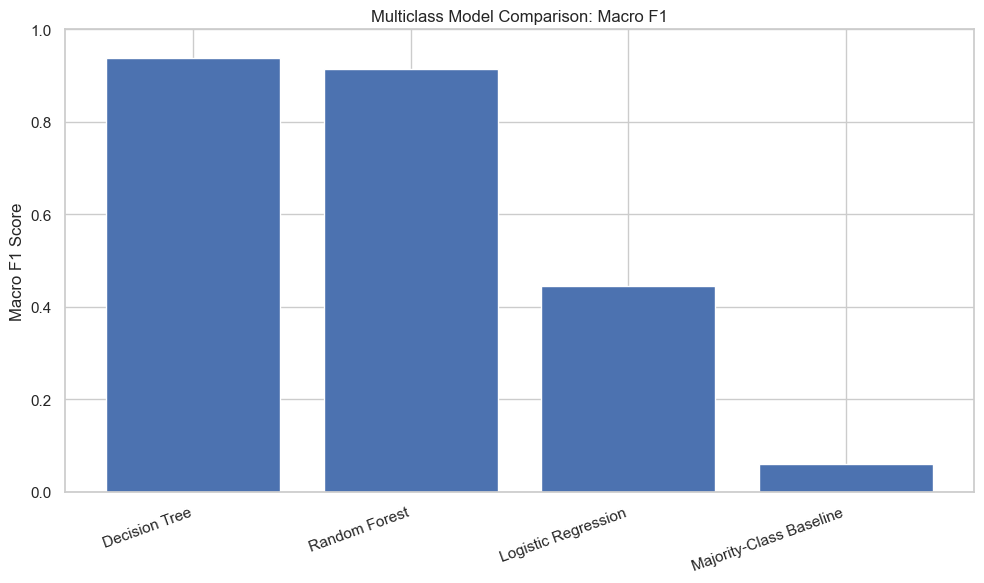

In [15]:
plt.figure(figsize=(10, 6))
plt.bar(results_df["Model"], results_df["Macro F1"])
plt.title("Multiclass Model Comparison: Macro F1")
plt.ylabel("Macro F1 Score")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

## 14. Confusion Matrix for the Best Model

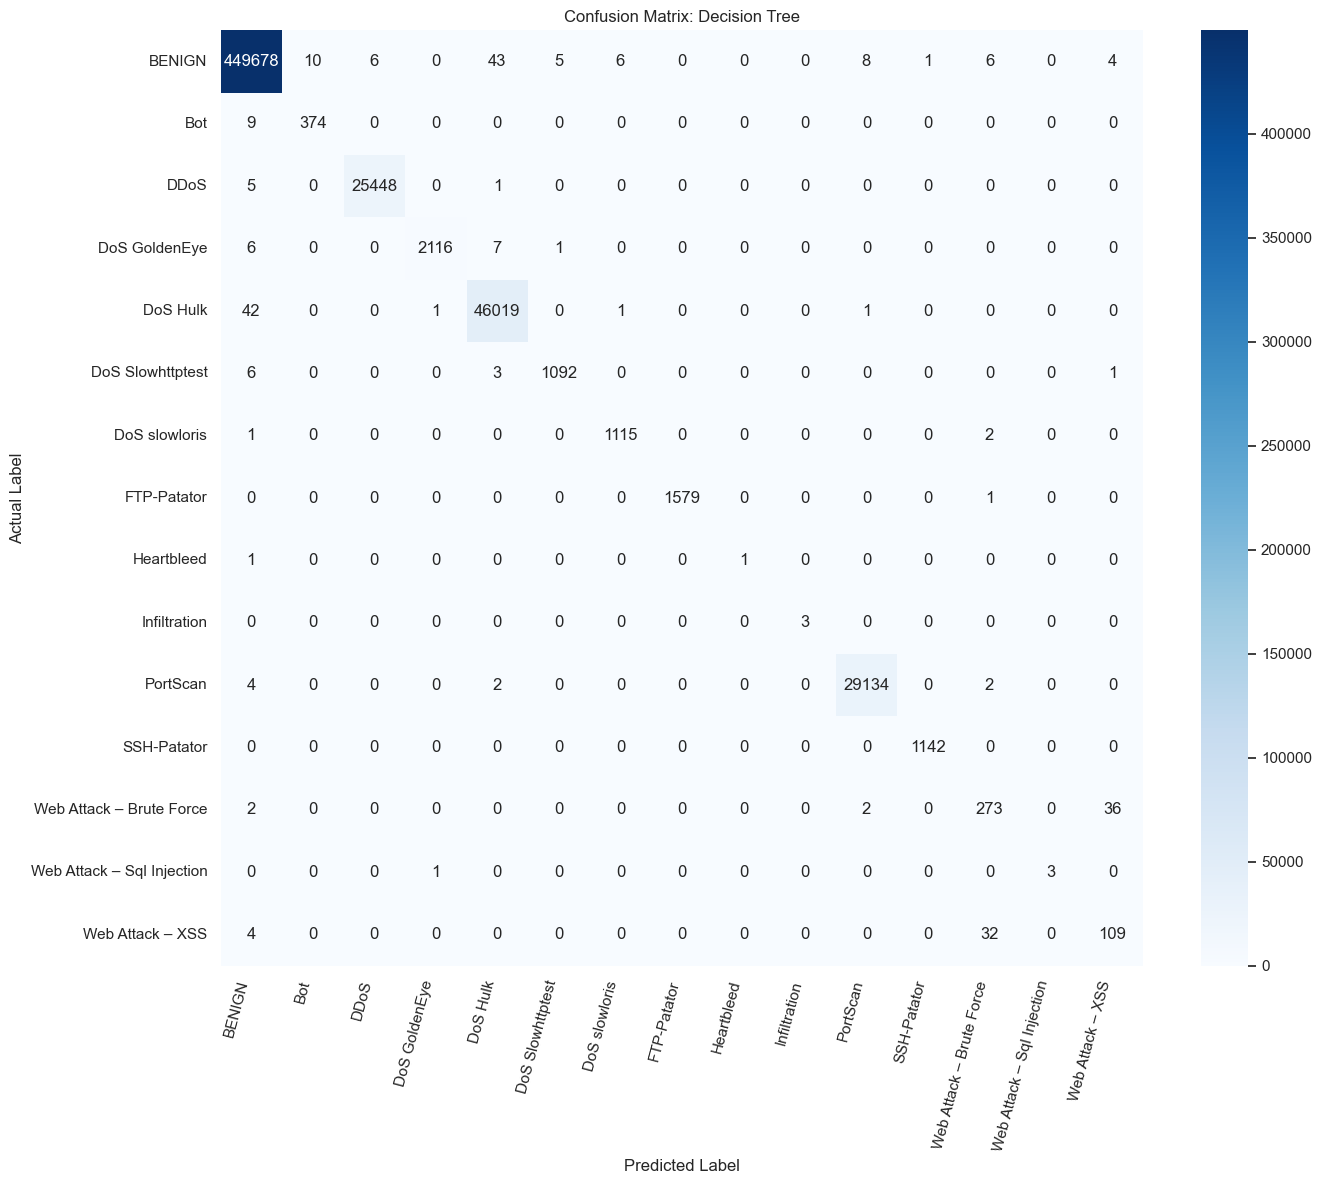

Best model based on Macro F1: Decision Tree


In [16]:
model_predictions = {
    "Majority-Class Baseline": baseline_predictions,
    "Logistic Regression": logistic_predictions,
    "Decision Tree": decision_tree_predictions,
    "Random Forest": random_forest_predictions,
}

best_model_name = results_df.loc[0, "Model"]
best_predictions = model_predictions[best_model_name]

class_labels = sorted(y_test.unique())
cm = confusion_matrix(y_test, best_predictions, labels=class_labels)

plt.figure(figsize=(14, 12))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)
plt.title(f"Confusion Matrix: {best_model_name}")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=75, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("Best model based on Macro F1:", best_model_name)

## 15. Random Forest Feature Importance

,Feature,Importance
1,Destination Port,0.076357
61,Init_Win_bytes_backward,0.061083
0,Source Port,0.056652
37,Bwd Packets/s,0.029646
63,min_seg_size_forward,0.027696
18,Flow IAT Mean,0.026897
60,Init_Win_bytes_forward,0.025862
54,Avg Bwd Segment Size,0.023479
8,Fwd Packet Length Max,0.023330
17,Flow Packets/s,0.021628


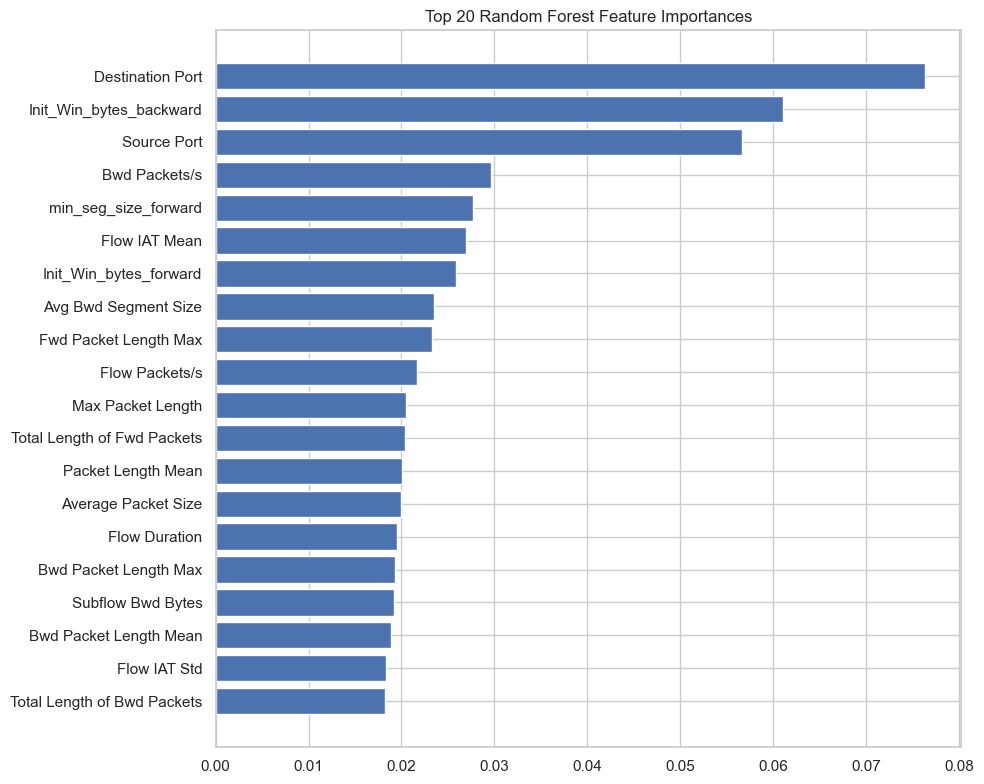

In [17]:
rf_classifier = random_forest_model.named_steps["classifier"]
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_classifier.feature_importances_
}).sort_values("Importance", ascending=False)

display(feature_importance.head(20))

plt.figure(figsize=(10, 8))
top_features = feature_importance.head(20).sort_values("Importance")
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 20 Random Forest Feature Importances")
plt.tight_layout()
plt.show()

## 16. Final Evaluation Summary

In [18]:
print("MULTICLASS CLASSIFICATION SUMMARY")
print("=" * 50)
print("Dataset rows used:", len(X))
print("Number of classes:", y.nunique())
print("Number of features:", X.shape[1])
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Best model:", best_model_name)
print("\\nFinal model comparison:")
display(results_df.round(4))

MULTICLASS CLASSIFICATION SUMMARY
Dataset rows used: 2791255
Number of classes: 15
Number of features: 72
Training rows: 2232906
Testing rows: 558349
Best model: Decision Tree
\nFinal model comparison:


,Model,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,Decision Tree,0.9995,0.9220,0.9699,0.9220,0.9392,0.9995
1,Random Forest,0.9994,0.8913,0.9738,0.8913,0.9148,0.9994
2,Logistic Regression,0.8483,0.8730,0.3759,0.8730,0.4451,0.8942
3,Majority-Class Baseline,0.8055,0.0667,0.0537,0.0667,0.0595,0.7188


## 17. Conclusion

The multiclass classification experiment compares a majority-class baseline with Logistic Regression, Decision Tree, and Random Forest using the same grouped test set. Macro F1 and balanced accuracy are emphasized because the dataset contains class imbalance and macro metrics give each class equal weight.

The best-performing model is selected based on Macro F1 on the held-out test set. The results describe performance on this dataset and split; they should not be interpreted as guaranteed real-world performance. Rare attack classes and possible dataset-specific patterns should be considered when interpreting the results.